Trabalho Prático UNOESC — Predição de demissões em tecnologia. Regressão (Regressão Linear Múltipla, KNN e MLP) sobre o dataset Tech Layoffs (Kaggle), com 1.745 registros e 18 colunas. O objetivo é estimar o número de demissões (Laid_Off) em eventos já registrados, e não prever se haverá demissão. Atributos derivados da própria demissão foram excluídos.

In [ ]:
from pathlib import Path
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from IPython.display import display
SEED=42
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Trabalho_Tech_Layoffs_DADOS_REAIS')
except ImportError:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if not (ROOT / 'data' / 'tech_layoffs.csv').exists():
    raise FileNotFoundError(f'CSV não encontrado em {ROOT / "data" / "tech_layoffs.csv"}. Consulte o README. No Colab, o nome da pasta no Drive deve corresponder a ROOT.')
OUT=ROOT/'reports'/'resultados'; OUT.mkdir(parents=True,exist_ok=True)
sns.set_theme(style='whitegrid')
print('Projeto:', ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto: /content/drive/MyDrive/Trabalho_Tech_Layoffs_DADOS_REAIS


## 1 — Carregamento e validação do dataset real

In [ ]:
source = ROOT/'data'/'tech_layoffs.csv'
df = pd.read_csv(source, low_memory=False)
df.columns = df.columns.str.strip()
required=['Company','Location_HQ','Region','USState','Country','Continent','Laid_Off','Date_layoffs','Percentage','Company_Size_before_Layoffs','Company_Size_after_layoffs','Industry','Stage','Money_Raised_in__mil','Year','latitude','longitude']
missing=sorted(set(required)-set(df.columns))
if missing: raise ValueError(f'Colunas obrigatórias ausentes: {missing}. Encontradas: {df.columns.tolist()}')
if len(df)<1000 or len(df.columns)<9: raise ValueError('Dataset não atende ao mínimo de 1.000 linhas e 8 atributos + alvo.')
if not any(df[c].dtype == 'object' for c in df.columns): raise ValueError('Sem variáveis categóricas.')
print(f'Base: {len(df)} registros, {len(df.columns)} colunas; duplicatas completas: {df.duplicated().sum()}')
display(df.head())
display(df.isna().sum().sort_values(ascending=False).to_frame('Valores ausentes'))


Base: 1745 registros, 18 colunas; duplicatas completas: 0


,Nr,Company,Location_HQ,Region,USState,Country,Continent,Laid_Off,Date_layoffs,Percentage,Company_Size_before_Layoffs,Company_Size_after_layoffs,Industry,Stage,Money_Raised_in__mil,Year,latitude,longitude
0,1,Tamara Mellon,Los Angeles,other,California,USA,North America,20.0,2020-03-12,40.0,50.0,30.0,Retail,Series C,90.0,2020,34.053691,-118.242766
1,2,HopSkipDrive,Los Angeles,other,California,USA,North America,8.0,2020-03-13,10.0,80.0,72.0,Transportation,Unknown,45.0,2020,34.053691,-118.242766
2,3,Panda Squad,San Francisco,San Francisco Bay Area,California,USA,North America,6.0,2020-03-13,75.0,8.0,2.0,Consumer,Seed,1.0,2020,37.779259,-122.419329
3,4,Help.com,Austin,other,Texas,USA,North America,16.0,2020-03-16,100.0,16.0,0.0,Support,Seed,6.0,2020,30.271129,-97.743700
4,5,Inspirato,Denver,other,Colorado,USA,North America,130.0,2020-03-16,22.0,591.0,461.0,Travel,Series C,79.0,2020,39.739236,-104.984862


,Valores ausentes
Money_Raised_in__mil,110
Stage,27
USState,1
Nr,0
Company,0
Location_HQ,0
Continent,0
Laid_Off,0
Region,0
Country,0


## 2 — Análise exploratória (Seaborn)

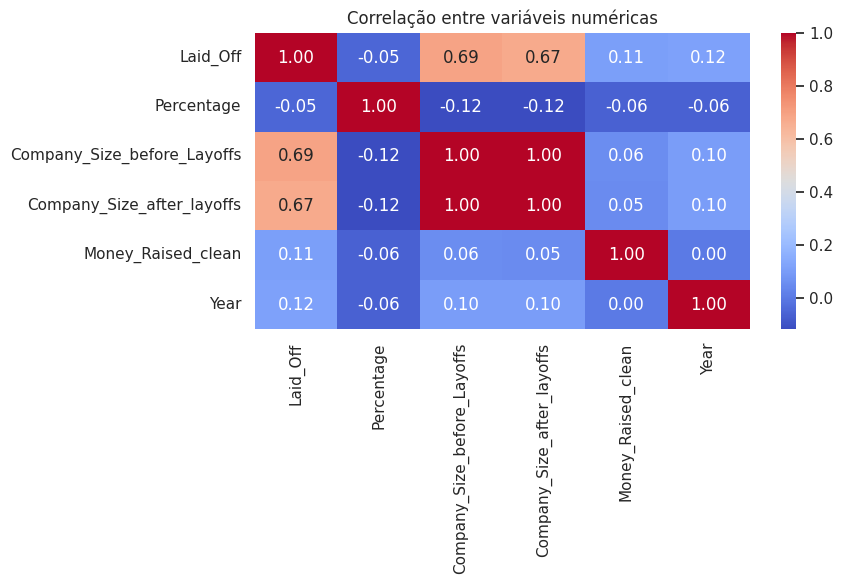

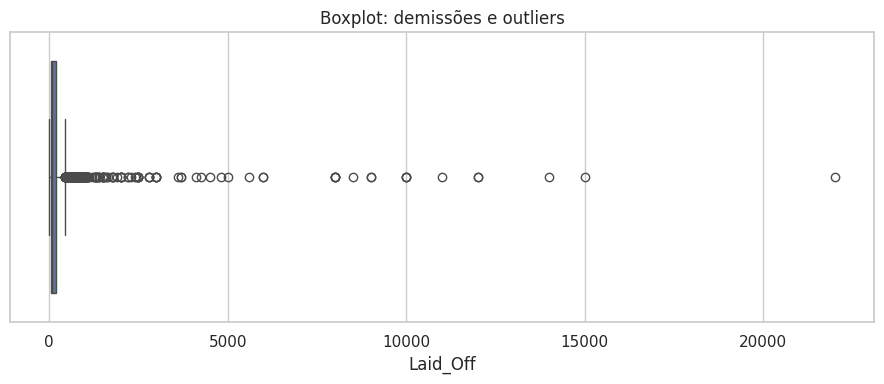

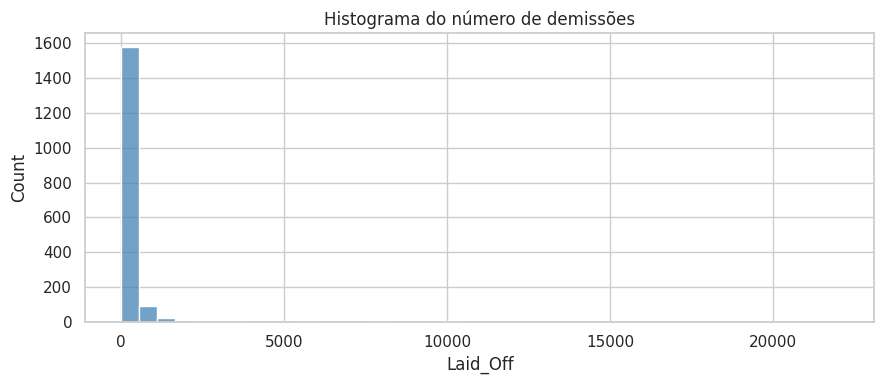

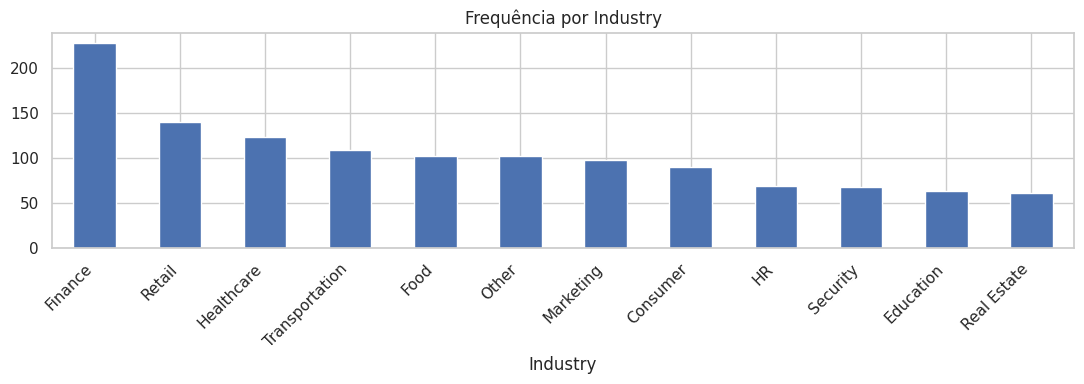

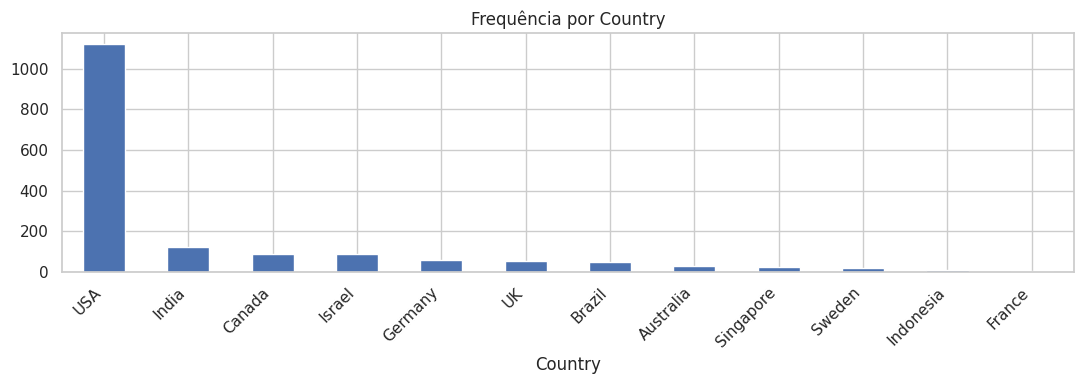

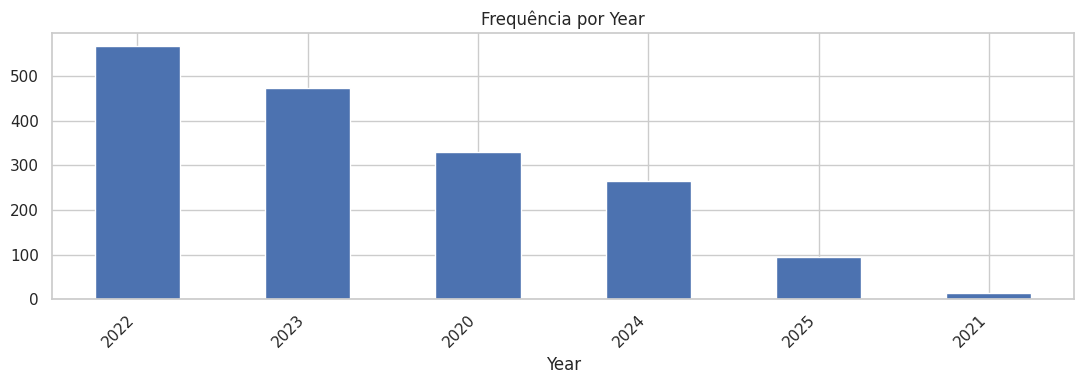

Mediana do alvo: 90.0 | Alvo faltante: 0


In [ ]:
eda=df.copy()
eda['Laid_Off']=pd.to_numeric(eda['Laid_Off'],errors='coerce')
for col in ['Percentage','Company_Size_before_Layoffs','Company_Size_after_layoffs','Year','latitude','longitude']:
    eda[col]=pd.to_numeric(eda[col],errors='coerce')
# valores monetários podem conter $, vírgulas, ou outros indicadores textuais:
eda['Money_Raised_clean']=pd.to_numeric(eda['Money_Raised_in__mil'].astype('string').str.replace(r'[^0-9.\-]','',regex=True),errors='coerce')
nums=['Laid_Off','Percentage','Company_Size_before_Layoffs','Company_Size_after_layoffs','Money_Raised_clean','Year']
fig,ax=plt.subplots(figsize=(9,6));sns.heatmap(eda[nums].corr(),annot=True,fmt='.2f',cmap='coolwarm',ax=ax);ax.set_title('Correlação entre variáveis numéricas');plt.tight_layout();plt.savefig(OUT/'heatmap.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(9,4));sns.boxplot(x=eda['Laid_Off'],ax=ax);ax.set_title('Boxplot: demissões e outliers');plt.tight_layout();plt.savefig(OUT/'boxplot.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(9,4));sns.histplot(eda['Laid_Off'].dropna(),bins=40,ax=ax,color='steelblue');ax.set_title('Histograma do número de demissões');plt.tight_layout();plt.savefig(OUT/'histograma.png',dpi=150);plt.show()
for col in ['Industry','Country','Year']:
    fig,ax=plt.subplots(figsize=(11,4));eda[col].fillna('Não informado').astype(str).value_counts().head(12).plot.bar(ax=ax);ax.set_title(f'Frequência por {col}');plt.xticks(rotation=45,ha='right');plt.tight_layout();plt.savefig(OUT/f'frequencia_{col}.png',dpi=150);plt.show()
print('Mediana do alvo:',eda['Laid_Off'].median(),'| Alvo faltante:',eda['Laid_Off'].isna().sum())


## 3 — Preparação e separação (Pipeline sem vazamento)
Não usar `Percentage` nem `Company_Size_after_layoffs` nas entradas. O ajuste dos imputadores, do codificador e do scaler será feito só nos dados de treino de cada fold.

In [ ]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

work=df.drop_duplicates().copy()
work['Laid_Off']=pd.to_numeric(work['Laid_Off'], errors='coerce')
work=work.loc[work['Laid_Off'].notna() & (work['Laid_Off'] >= 0)].copy()
work['Money_Raised_clean']=pd.to_numeric(work['Money_Raised_in__mil'],errors='coerce')
work['Company_Size_before_Layoffs']=pd.to_numeric(work['Company_Size_before_Layoffs'],errors='coerce')
work['Date_layoffs']=pd.to_datetime(work['Date_layoffs'],errors='coerce')
work['month']=work['Date_layoffs'].dt.month
work['year']=pd.to_numeric(work['Year'],errors='coerce')
# 'Percentage', 'Company_Size_after_layoffs' e 'Nr' ficam de fora por vazamento ou irrelevância.
# A data do evento e o porte anterior da empresa só serão conhecidos em cenários bem definidos.
cats=['Country','Continent','Industry','Stage']
nums=['Company_Size_before_Layoffs','Money_Raised_clean','year','month']
X=work[cats+nums].copy()
y=work['Laid_Off'].astype('float64').copy()
for col in cats:
    X[col]=X[col].astype(object).where(X[col].notna(),np.nan)
for col in nums:
    X[col]=pd.to_numeric(X[col],errors='coerce').astype('float64')
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=SEED)
prep=ColumnTransformer([
 ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),nums),
 ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cats)
])
assert not any(value is pd.NA for value in X_train.to_numpy().flat), 'pd.NA permaneceu nas entradas'
print(f'Treino: {len(X_train)}, teste: {len(X_test)}, features originais: {len(X.columns)}')


Treino: 1396, teste: 349, features originais: 8


## 4 — Modelagem e otimização
Usamos `GridSearchCV` com **5 folds**, `Pipeline` ajustado dentro de cada fold e transformação `log1p` do alvo para reduzir assimetria. A Regressão Linear é uma referência (sem hiperparâmetros relevantes exigidos para busca); o KNN testa `n_neighbors`, `weights`, `metric`; a MLP testa `hidden_layer_sizes`, `activation`, `alpha`. Cada teste avalia MAE na escala original de número de funcionários. A grade da MLP pode demorar no Colab.

In [ ]:
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
models={
    'Regressão Linear Múltipla':(LinearRegression(),{}),
    'KNN':(KNeighborsRegressor(),{
        'model__n_neighbors':[3,7,15],
        'model__weights':['uniform','distance'],
        'model__metric':['euclidean','manhattan']}),
    'MLP':(MLPRegressor(random_state=SEED,max_iter=400,early_stopping=True,n_iter_no_change=15),{
        'model__hidden_layer_sizes':[(32,),(64,32)],
        'model__activation':['relu','tanh'],
        'model__alpha':[0.001,0.1]})
}
results=[];predictions={};tuning=[];fitted={}
for name,(model,params) in models.items():
    print('Treinando:',name,flush=True)
    pipe=Pipeline([('prep',prep),('model',model)])
    estimator=TransformedTargetRegressor(regressor=pipe,func=np.log1p,inverse_func=np.expm1)
    grid={f'regressor__{key}':val for key,val in params.items()}
    gs=GridSearchCV(estimator,grid or [{}],cv=cv,scoring='neg_mean_absolute_error',n_jobs=1,refit=True,error_score='raise')
    gs.fit(X_train,y_train)
    pred=np.maximum(gs.predict(X_test),0)
    predictions[name]=pred;fitted[name]=gs
    results.append({'Modelo':name,'R2':r2_score(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'MAE':mean_absolute_error(y_test,pred)})
    tuning.append({'Modelo':name,'Valores testados':str(params) if params else 'sem grade (baseline)','Melhores parâmetros':str(gs.best_params_) if params else 'padrão','MAE médio CV':-gs.best_score_})
    print(f'Concluído: {name} | MAE teste: {results[-1]["MAE"]:.2f}',flush=True)
metrics=pd.DataFrame(results).sort_values('MAE')
table=pd.DataFrame(tuning)
display(table);display(metrics)
table.to_csv(OUT/'melhores_parametros.csv',index=False)
metrics.to_csv(OUT/'metricas_teste.csv',index=False)


Treinando: Regressão Linear Múltipla
Concluído: Regressão Linear Múltipla | MAE teste: 884.24
Treinando: KNN
Concluído: KNN | MAE teste: 258.29
Treinando: MLP
Concluído: MLP | MAE teste: 236.03


,Modelo,Valores testados,Melhores parâmetros,MAE médio CV
0,Regressão Linear Múltipla,sem grade (baseline),padrão,101025.850995
1,KNN,"{'model__n_neighbors': [3, 7, 15], 'model__weights': ['uniform', 'distance'], 'model__metric': ['euclidean', 'manhattan']}","{'regressor__model__metric': 'euclidean', 'regressor__model__n_neighbors': 7, 'regressor__model__weights': 'distance'}",210.186686
2,MLP,"{'model__hidden_layer_sizes': [(32,), (64, 32)], 'model__activation': ['relu', 'tanh'], 'model__alpha': [0.001, 0.1]}","{'regressor__model__activation': 'tanh', 'regressor__model__alpha': 0.1, 'regressor__model__hidden_layer_sizes': (64, 32)}",201.190731


,Modelo,R2,RMSE,MAE
2,MLP,0.553683,851.531336,236.025689
1,KNN,0.518634,884.335046,258.293020
0,Regressão Linear Múltipla,-41.727728,8331.705834,884.244865


## 5 — Gráficos, resíduos e comparação

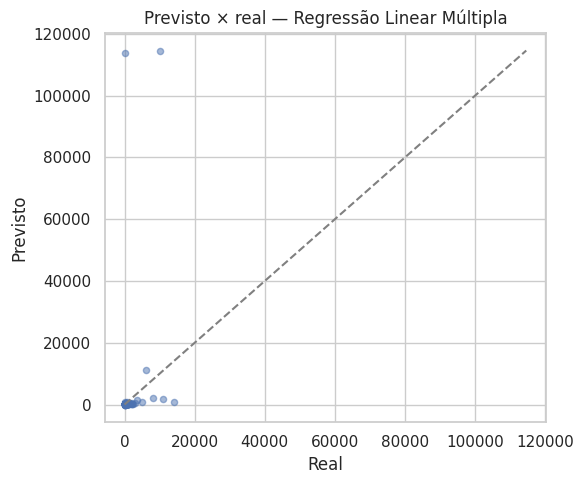

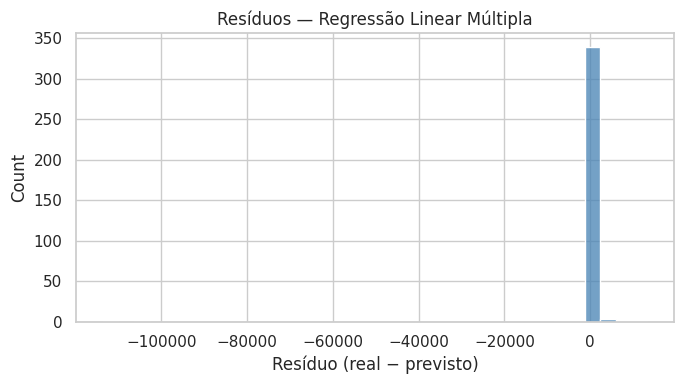

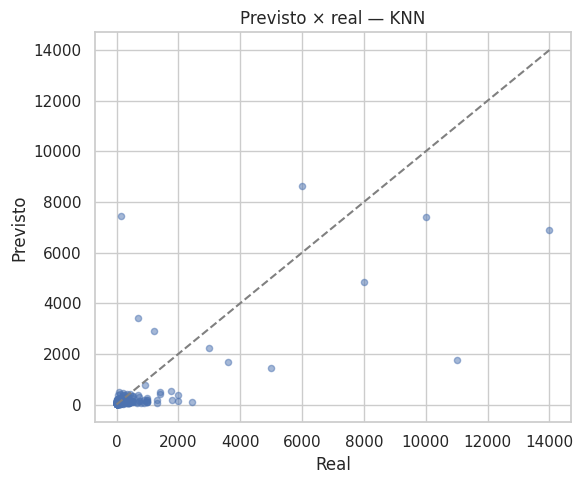

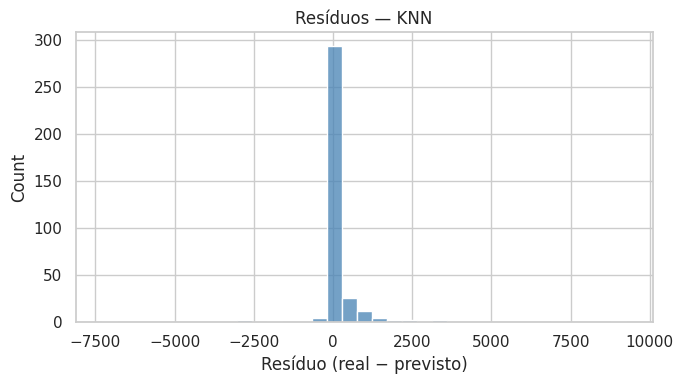

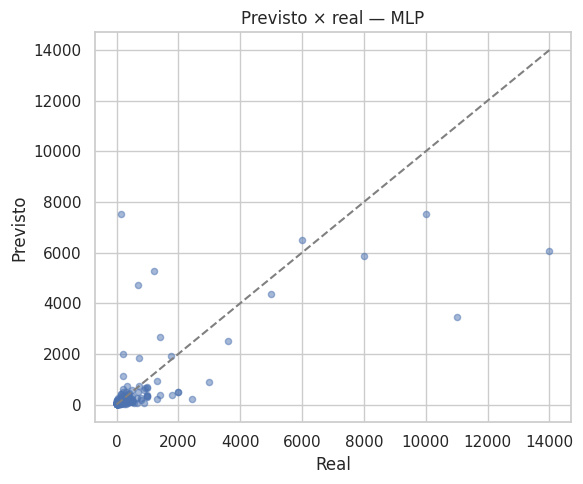

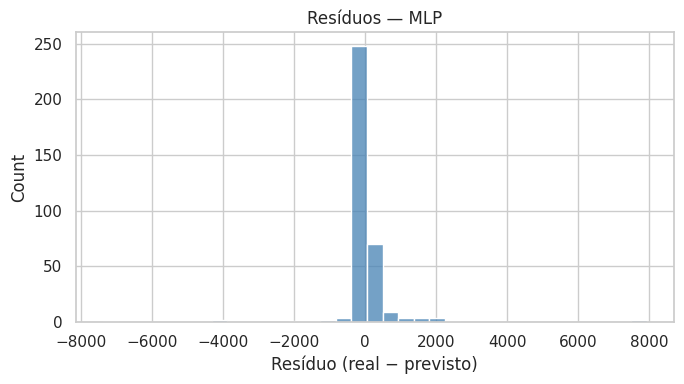

Menor MAE no conjunto de teste: MLP
Interprete também RMSE, R², outliers e os resíduos antes de concluir qual modelo é melhor.


In [ ]:
for name,pred in predictions.items():
    key=name.replace(' ','_').replace('ã','a').replace('ú','u')
    fig,ax=plt.subplots(figsize=(6,5));ax.scatter(y_test,pred,alpha=.5,s=20)
    high=max(float(y_test.max()),float(np.max(pred)),1)
    ax.plot([0,high],[0,high],'--',color='gray');ax.set(xlabel='Real',ylabel='Previsto',title=f'Previsto × real — {name}')
    plt.tight_layout();plt.savefig(OUT/f'previsto_real_{key}.png',dpi=150);plt.show()
    fig,ax=plt.subplots(figsize=(7,4));sns.histplot(y_test.to_numpy()-pred,bins=35,ax=ax,color='steelblue')
    ax.set(xlabel='Resíduo (real − previsto)',title=f'Resíduos — {name}')
    plt.tight_layout();plt.savefig(OUT/f'residuos_{key}.png',dpi=150);plt.show()
print('Menor MAE no conjunto de teste:',metrics.iloc[0]['Modelo'])
print('Interprete também RMSE, R², outliers e os resíduos antes de concluir qual modelo é melhor.')


## 6 — Interpretação e limitações
Examine R², MAE, RMSE e os dois gráficos de cada modelo. Não basta declarar o menor MAE; destaque variabilidade e erros em eventos maiores.

**Limitações:** prevê quantidade de demissões *em eventos já registrados*, não prevê se haverá demissões. `Company_Size_before_Layoffs` é um atributo fortemente informativo, mas sua disponibilidade antes do evento deve ser justificada. `Year` e `month` pressupõem um período de previsão definido. O particionamento aleatório não testa previsão de anos futuros; empresas podem aparecer em mais de um evento.


In [ ]:
print(fitted['KNN'].best_params_)
print(fitted['MLP'].best_params_)

{'regressor__model__metric': 'euclidean', 'regressor__model__n_neighbors': 7, 'regressor__model__weights': 'distance'}
{'regressor__model__activation': 'tanh', 'regressor__model__alpha': 0.1, 'regressor__model__hidden_layer_sizes': (64, 32)}
